In [11]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an MLP for MNIST
- Training and evaluating an MLP

# Import libraries

In [12]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()
train_set = datasets.MNIST('./data', train=True, download=True, transform=transform)
test_set = datasets.MNIST('./data', train=False, download=True, transform=transform)
x_train = train_set.data.float().unsqueeze(1).div(255).to(device)
y_train = train_set.targets.long().to(device)
x_test = test_set.data.float().unsqueeze(1).div(255).to(device)
y_test = test_set.targets.long().to(device)
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

60000 train samples
10000 test samples


In [13]:
num_classes = 10

In [20]:
class MNISTMLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 512)
        self.dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)
        self.dropout2 = nn.Dropout(0.2)
        self.fc3 = nn.Linear(512, num_classes)

    def features(self, x):
        x = torch.relu(self.fc1(self.flatten(x)))
        x = self.dropout1(x)
        x = torch.relu(self.fc2(x))
        return self.dropout2(x)

    def forward(self, x):
        return self.fc3(self.features(x))

model = MNISTMLP().to(device)
print(model)

MNISTMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (dropout1): Dropout(p=0.2, inplace=False)
  (fc2): Linear(in_features=512, out_features=512, bias=True)
  (dropout2): Dropout(p=0.2, inplace=False)
  (fc3): Linear(in_features=512, out_features=10, bias=True)
)


# (1) Data

In [21]:
lr = 0.01
batch_size = 128
epochs = 30

# (2) Declare model

In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.0)
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=batch_size, shuffle=True)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=batch_size)

def evaluate(loader):
    model.eval(); total_loss = 0.0; correct = 0; count = 0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb); total_loss += criterion(logits, yb).item() * yb.size(0)
            correct += (logits.argmax(1) == yb).sum().item(); count += yb.size(0)
    return total_loss / count, correct / count

history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
starting_time = time.time()
for epoch in range(epochs):
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad(); loss_value = criterion(model(xb), yb); loss_value.backward(); optimizer.step()
    train_loss, train_acc = evaluate(train_loader)
    val_loss, val_acc = evaluate(test_loader)
    history['loss'].append(train_loss); history['accuracy'].append(train_acc)
    history['val_loss'].append(val_loss); history['val_accuracy'].append(val_acc)
    print(f'Epoch {epoch + 1}/{epochs}: loss={train_loss:.4f}, accuracy={train_acc:.4f}, val_accuracy={val_acc:.4f}')
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/30: loss=1.6443, accuracy=0.7377, val_accuracy=0.7430
Epoch 2/30: loss=0.6858, accuracy=0.8372, val_accuracy=0.8425
Epoch 3/30: loss=0.4871, accuracy=0.8672, val_accuracy=0.8735
Epoch 4/30: loss=0.4106, accuracy=0.8871, val_accuracy=0.8909
Epoch 5/30: loss=0.3722, accuracy=0.8951, val_accuracy=0.8988
Epoch 6/30: loss=0.3452, accuracy=0.9017, val_accuracy=0.9051
Epoch 7/30: loss=0.3266, accuracy=0.9069, val_accuracy=0.9094
Epoch 8/30: loss=0.3100, accuracy=0.9108, val_accuracy=0.9152
Epoch 9/30: loss=0.2957, accuracy=0.9150, val_accuracy=0.9171
Epoch 10/30: loss=0.2831, accuracy=0.9179, val_accuracy=0.9221
Epoch 11/30: loss=0.2712, accuracy=0.9215, val_accuracy=0.9256
Epoch 12/30: loss=0.2606, accuracy=0.9241, val_accuracy=0.9266
Epoch 13/30: loss=0.2503, accuracy=0.9275, val_accuracy=0.9299
Epoch 14/30: loss=0.2406, accuracy=0.9298, val_accuracy=0.9333
Epoch 15/30: loss=0.2314, accuracy=0.9329, val_accuracy=0.9353
Epoch 16/30: loss=0.2240, accuracy=0.9351, val_accuracy=0.9375
E

Test loss: 0.14554187596738338
Test accuracy: 0.9558


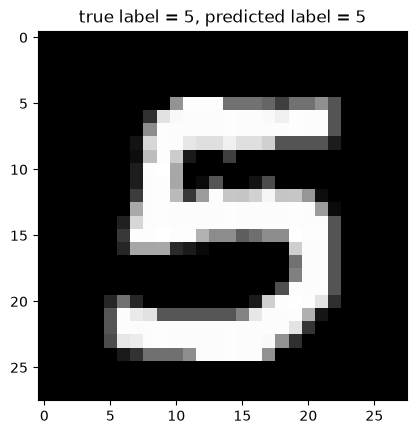

In [17]:
test_loss, test_accuracy = evaluate(test_loader)
print('Test loss:', test_loss)
print('Test accuracy:', test_accuracy)

random_test_index = np.random.randint(len(test_set))
test_img = x_test[random_test_index:random_test_index + 1]
test_label = y_test[random_test_index].item()
model.eval()
with torch.no_grad():
    pred_label = model(test_img).argmax(1).item()
plt.imshow(test_img[0, 0].cpu(), cmap='gray')
plt.title(f'true label = {test_label}, predicted label = {pred_label}')
plt.show()

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [22]:
# PyTorch equivalent of model.predict and intermediate feature extraction
model.eval()
with torch.no_grad():
    y_pred = torch.softmax(model(test_img), dim=1)
    y_feat = model.features(test_img)
print('prediction shape:', y_pred.shape, 'feature shape:', y_feat.shape)

prediction shape: torch.Size([1, 10]) feature shape: torch.Size([1, 512])


### Training time
- Training time with GTX 1080 is about 1.4402 minutes for 30 epochs
- Training time with Core i7 is around 3.0493 minutes for 30 epochs

# (4) Evaluate trained model

In [19]:
y_feat.shape, y_pred.shape

(torch.Size([1, 512]), torch.Size([1, 10]))